In [24]:
options(repr.plot.res = 250, repr.plot.width = 5, repr.plot.height = 3)

In [25]:
library('tidymodels')

gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


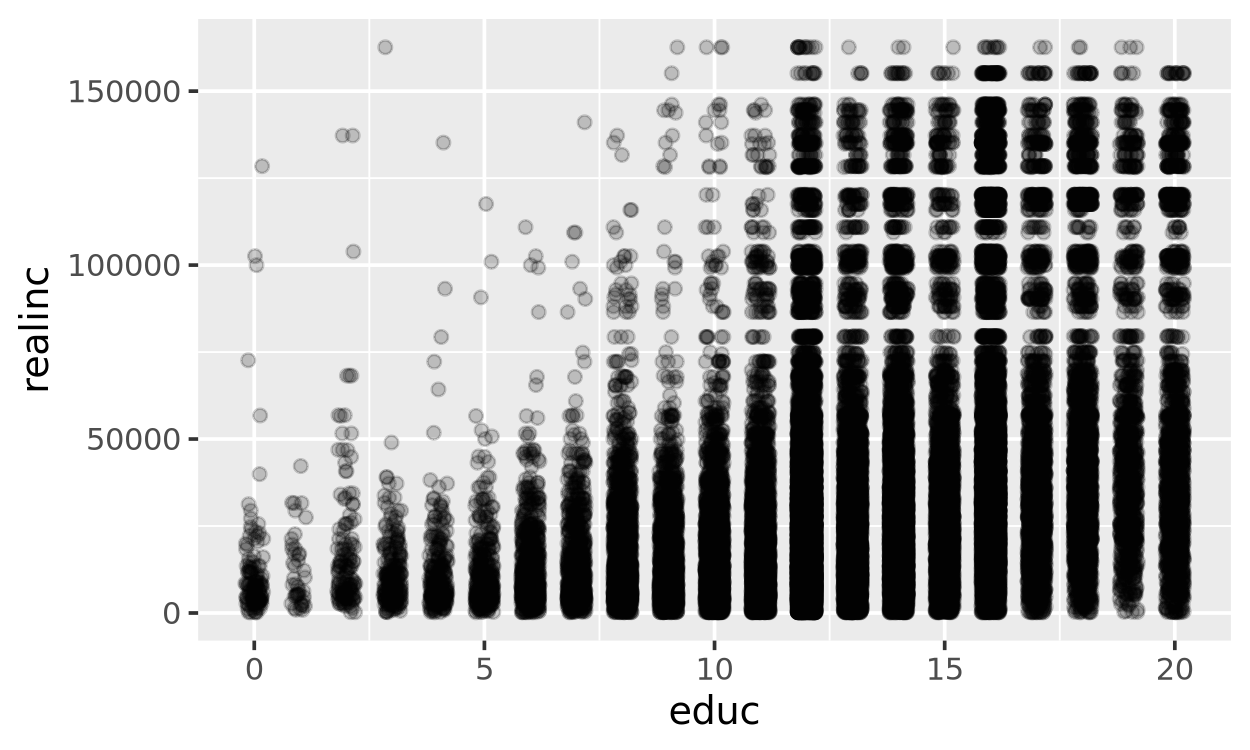

In [26]:
gss |>
ggplot(aes(x = educ, y = realinc)) +
geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height = 0.2))

In [27]:
set.seed(123)

n_params <- 250

params <- tibble(
  id = 1:n_params,
  intercept = runif(n_params, 0, 40000),
  slope = runif(n_params, 0, 8000)
)

params |> glimpse()

Rows: 250
Columns: 3
$ id        <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> 11503.101, 31532.205, 16359.077, 35320.696, 37618.691, 1822.…
$ slope     <dbl> 2057.73397, 1774.30348, 4744.36521, 2140.17146, 4248.56319, …


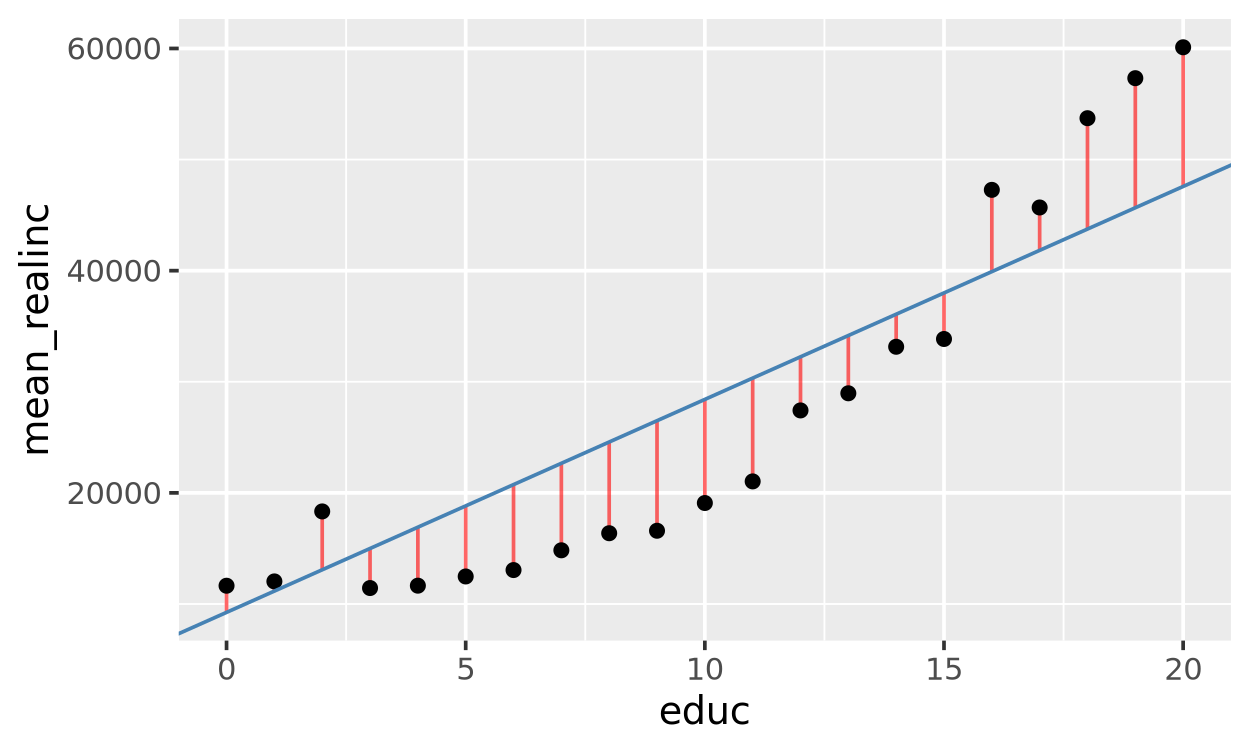

In [33]:
best <- params |>
  mutate(rmse = map2_dbl(intercept, slope, calc_rmse)) |>
  slice_min(rmse, n = 1)

gss |>
  filter(!is.na(educ)) |>
  group_by(educ) |>
  summarize(mean_realinc = mean(realinc, na.rm = TRUE)) |>
  mutate(predicted = best$intercept + best$slope * educ) |>
  ggplot(aes(x = educ, y = mean_realinc)) +
  geom_segment(aes(xend = educ, yend = predicted), color = "red", alpha = 0.6) +
  geom_point() +
  geom_abline(
    data = best,
    aes(slope = slope, intercept = intercept),
    color = "steelblue"
  )

Steps for creating a model:

1. Pick the model form:
$$\text{realinc}_i = \text{intercept} + \text{slope} \cdot \text{educ}_i $$
3. Design a way to evaluate different model parameters.
4. Optimize our parameter values. 

In [32]:
calc_rmse <- function(intercept, slope, data = gss) {
  data |>
    filter(!is.na(educ), !is.na(realinc)) |>
    summarize(
      rmse = sqrt(mean((realinc - (intercept + slope * educ))^2))) |>
    pull(rmse)}

calc_rmse(intercept = 0, slope = 2500)

[1] 28504.88

In [30]:
params <- params |>
  mutate(rmse = map2_dbl(intercept, slope, calc_rmse))

params |>
  arrange(rmse) |>
  slice_head(n = 10)

params |> glimpse()

Rows: 250
Columns: 4
$ id        <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> 11503.101, 31532.205, 16359.077, 35320.696, 37618.691, 1822.…
$ slope     <dbl> 2057.73397, 1774.30348, 4744.36521, 2140.17146, 4248.56319, …
$ rmse      <dbl> 29325.18, 36482.70, 54301.50, 42153.04, 67220.60, 59716.83, …
